# Fleet insights

Age distributions from the FAA registry (`reg/hex/*.json`, all ~317k US registrations) and utilization from the
ADS-B flight history (`hist/*.json`). Owner names only exist for organizations; private owners were filtered out
in the pipeline and never reach these files.

In [1]:
import json, os, re
from pathlib import Path
import numpy as np
import polars as pl
import matplotlib.pyplot as plt

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = Path(os.environ.get("TAILTALE_OUT", REPO / "out" / "data"))
assert (DATA / "reg").exists(), f"run the pipeline first (looked in {DATA})"

# Chart style: thin marks, recessive axes, the site's palette.
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e", "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True, "font.size": 10,
})

def load_shards(sub):
    out = {}
    for p in sorted((DATA / sub).glob("*.json")):
        out.update(json.loads(p.read_bytes()))
    return out

AIRLINER_TYPES = {
    "A319","A320","A321","A20N","A21N","BCS1","BCS3","A332","A333","A339","A359","A35K","A388","B712","B737","B738",
    "B739","B38M","B39M","B752","B753","B763","B764","B772","B77W","B77L","B788","B789","B78X","B744","B748","E170",
    "E75L","E75S","E190","E195","E290","CRJ2","CRJ7","CRJ9","CRJX","AT76","DH8D","MD11","A306",
}

def headline(key, items):
    """Merge this notebook's headline numbers into web/src/headlines.json (shown on the Data Quality page)."""
    p = REPO / "web" / "src" / "headlines.json"
    cur = json.loads(p.read_text()) if p.exists() else {}
    cur.setdefault("sections", {})[key] = items
    cur.pop("items", None)
    run = json.loads((DATA / "quality" / "run.json").read_text())
    cur["as_of"] = f"history day {run['d']}, FAA registry {json.loads((DATA / 'reg' / 'meta.json').read_text())['built_at'][:10]}"
    p.write_text(json.dumps(cur, indent=2) + "\n")
    for i in items:
        print("•", i)

In [2]:
reg = pl.DataFrame(list(load_shards("reg/hex").values()), infer_schema_length=None)
active = reg.filter(pl.col("status").is_in(["V", "T", "M"]))
jets = active.filter((pl.col("eng_type") == "Turbofan") & (pl.col("seats") >= 50) & pl.col("year").is_not_null())
jets = jets.with_columns((2026 - pl.col("year")).alias("age"), (pl.col("mfr") + " " + pl.col("model")).alias("type"))
print(f"{reg.height:,} registrations, {active.height:,} valid, {jets.height:,} turbofan aircraft with 50+ seats")

317,604 registrations, 312,174 valid, 8,126 turbofan aircraft with 50+ seats


## 1. How old are US airliners?

In [3]:
top = jets.group_by("type").agg(pl.len().alias("n"), pl.col("age").median().alias("median_age"),
                                pl.col("age").quantile(0.25).alias("p25"), pl.col("age").quantile(0.75).alias("p75"),
                                pl.col("age").max().alias("oldest")).filter(pl.col("n") >= 60).sort("n", descending=True).head(15)
top

type,n,median_age,p25,p75,oldest
str,u32,f64,f64,f64,i64
"""Boeing 737-800""",891,16.0,12.0,25.0,28
"""Embraer E175""",615,10.0,8.0,12.0,19
"""Boeing 737 MAX 8""",582,3.0,1.0,4.0,11
"""Airbus A320-200""",518,20.0,14.0,26.0,34
"""Airbus A321-200""",464,10.0,9.0,12.0,29
…,…,…,…,…,…
"""Embraer ERJ-145""",294,23.0,22.0,25.0,29
"""Boeing 757-200""",282,32.0,28.0,35.0,44
"""Airbus A320neo""",223,5.0,4.0,8.0,10


/var/folders/z3/cvd0l8hs2zjgp7svdxvc0v440000gn/T/ipykernel_87840/2233222387.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax.boxplot(data, vert=False, widths=0.55, patch_artist=True, showfliers=False,


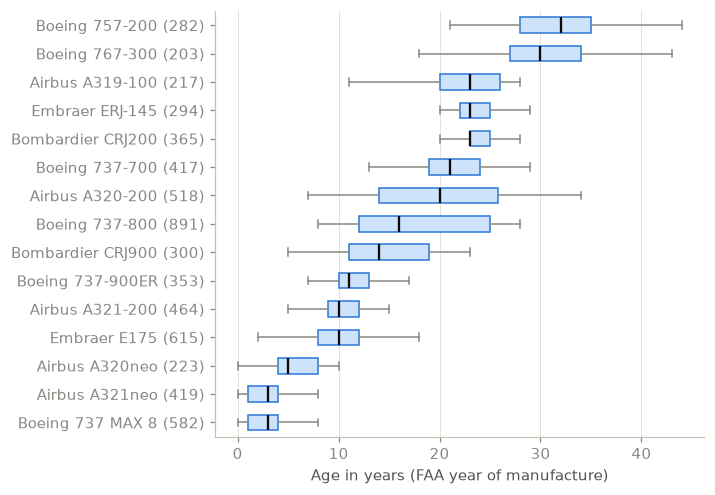

In [4]:
order = top.sort("median_age")["type"].to_list()
fig, ax = plt.subplots(figsize=(6.6, 4.6))
data = [jets.filter(pl.col("type") == t)["age"].to_numpy() for t in order]
bp = ax.boxplot(data, vert=False, widths=0.55, patch_artist=True, showfliers=False,
                medianprops={"color": INK, "linewidth": 1.5}, whiskerprops={"color": MUTED}, capprops={"color": MUTED},
                boxprops={"facecolor": "#cde2fb", "edgecolor": BLUE})
ax.set_yticks(range(1, len(order) + 1), [f"{t} ({len(d):,})" for t, d in zip(order, data)])
ax.set_xlabel("Age in years (FAA year of manufacture)"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

## 2. Who owns the airliners?

The registered owner is frequently a bank or trust acting as trustee for a lessor, not the airline whose paint is on the plane.

In [5]:
own = jets.with_columns(
    pl.when(pl.col("owner_org").str.contains(r"TRUST|BANK|TRUSTEE|LEASING|CAPITAL|FINANCE")).then(pl.lit("Bank, trust or lessor"))
      .when(pl.col("owner_org").is_null()).then(pl.lit("Not listed"))
      .otherwise(pl.lit("Operator / other company")).alias("owner_class"))
own_share = own.group_by("owner_class").agg(pl.len().alias("n")).with_columns((pl.col("n") / pl.col("n").sum()).alias("share")).sort("n", descending=True)
print(own_share)
print(own.filter(pl.col("owner_class") == "Bank, trust or lessor").group_by("owner_org").len().sort("len", descending=True).head(8))

shape: (3, 3)
┌──────────────────────────┬──────┬──────────┐
│ owner_class              ┆ n    ┆ share    │
│ ---                      ┆ ---  ┆ ---      │
│ str                      ┆ u32  ┆ f64      │
╞══════════════════════════╪══════╪══════════╡
│ Operator / other company ┆ 6370 ┆ 0.783904 │
│ Bank, trust or lessor    ┆ 1743 ┆ 0.214497 │
│ Not listed               ┆ 13   ┆ 0.0016   │
└──────────────────────────┴──────┴──────────┘
shape: (8, 2)
┌─────────────────────────────────┬─────┐
│ owner_org                       ┆ len │
│ ---                             ┆ --- │
│ str                             ┆ u32 │
╞═════════════════════════════════╪═════╡
│ BANK OF UTAH TRUSTEE            ┆ 686 │
│ UMB BANK NA TRUSTEE             ┆ 429 │
│ WILMINGTON TRUST CO TRUSTEE     ┆ 388 │
│ WELLS FARGO TRUST CO NA TRUSTE… ┆ 52  │
│ TVPX AIRCRAFT SOLUTIONS INC TR… ┆ 23  │
│ UMB BANK N A TRUSTEE            ┆ 22  │
│ WILMINGTON TRUST COMPANY TRUST… ┆ 17  │
│ U S BANK NA TRUSTEE             ┆ 11  │
└──

## 3. Utilization: how hard do they work?

Flights and airborne hours per airframe per day it was seen flying, joined to the registry by hex. Only completed days in the history window are used.

In [6]:
hist = load_shards("hist")
rows = [{"hex": h, "d": d["d"], "flights": len(d["flights"]), "hours": d["airborne_mins"] / 60, "t": e.get("t"),
         "airline": next((f["cs"][:3] for f in d["flights"] if f.get("cs") and re.match(r"^[A-Z]{3}\d", f["cs"])), None)}
        for h, e in hist.items() for d in e.get("days", [])]
days = pl.DataFrame(rows).join(jets.select("hex", "type", "age"), on="hex", how="inner")
airlines = json.loads((REPO / "worker" / "src" / "generated" / "airlines.json").read_text())
icao_name = {v["icao"]: v["name"] for v in airlines.values()}
util_type = days.group_by("type").agg(pl.len().alias("airframe_days"), pl.col("flights").mean().alias("flights_per_day"),
                                      pl.col("hours").mean().alias("hours_per_day")).filter(pl.col("airframe_days") >= 40).sort("hours_per_day", descending=True)
util_air = (days.filter(pl.col("airline").is_not_null()).group_by("airline")
            .agg(pl.len().alias("airframe_days"), pl.col("flights").mean().alias("flights_per_day"), pl.col("hours").mean().alias("hours_per_day"))
            .filter(pl.col("airframe_days") >= 60).sort("hours_per_day", descending=True)
            .with_columns(pl.col("airline").replace_strict(icao_name, default=pl.col("airline")).alias("name")))
print(util_type.head(12)); print(util_air.head(15))

shape: (12, 4)
┌───────────────────┬───────────────┬─────────────────┬───────────────┐
│ type              ┆ airframe_days ┆ flights_per_day ┆ hours_per_day │
│ ---               ┆ ---           ┆ ---             ┆ ---           │
│ str               ┆ u32           ┆ f64             ┆ f64           │
╞═══════════════════╪═══════════════╪═════════════════╪═══════════════╡
│ Airbus A321-200   ┆ 392           ┆ 4.091837        ┆ 8.659311      │
│ Airbus A321neo    ┆ 352           ┆ 3.792614        ┆ 8.419271      │
│ Boeing 737 MAX 8  ┆ 552           ┆ 4.833333        ┆ 8.240187      │
│ Boeing 737-700    ┆ 302           ┆ 5.625828        ┆ 7.692715      │
│ Airbus A220-300   ┆ 146           ┆ 4.253425        ┆ 7.59121       │
│ …                 ┆ …             ┆ …               ┆ …             │
│ Airbus A319-100   ┆ 174           ┆ 4.982759        ┆ 6.80977       │
│ Embraer E175      ┆ 575           ┆ 5.361739        ┆ 6.701043      │
│ Bombardier CRJ900 ┆ 235           ┆ 5.919149   

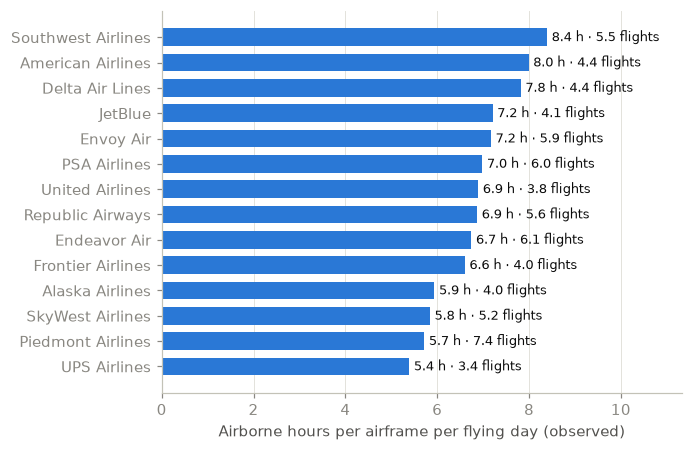

In [7]:
u = util_air.head(14).sort("hours_per_day")
fig, ax = plt.subplots(figsize=(6.4, 4.2))
ax.barh(u["name"], u["hours_per_day"], color=BLUE, height=0.7)
for i, (h, f) in enumerate(zip(u["hours_per_day"], u["flights_per_day"])):
    ax.text(h + 0.1, i, f"{h:.1f} h · {f:.1f} flights", va="center", fontsize=8.5, color=INK)
ax.set_xlabel("Airborne hours per airframe per flying day (observed)"); ax.grid(axis="y", visible=False)
ax.set_xlim(0, u["hours_per_day"].max() * 1.35)
plt.tight_layout(); plt.show()

## 4. Something surprising: who opts out of tracking?

Aircraft in the FAA LADD/PIA privacy programs keep only a stub in our history. Joining those stubs to the registry shows which kinds of aircraft opt out. Note the difference between *count* (piston aircraft are most numerous) and *rate* (business jets opt out far more often).

In [8]:
blocked = pl.DataFrame({"hex": [h for h, e in hist.items() if e.get("blocked")]})
b = blocked.join(active.select("hex", "eng_type", "seats", "owner_kind"), on="hex", how="left")
seen = pl.DataFrame({"hex": list(hist.keys())}).join(active.select("hex", "eng_type", "seats"), on="hex", how="inner")
def kind(df):
    return df.with_columns(pl.when((pl.col("eng_type") == "Turbofan") & (pl.col("seats") < 20)).then(pl.lit("Business jet"))
        .when(pl.col("eng_type") == "Turbofan").then(pl.lit("Airliner"))
        .when(pl.col("eng_type") == "Turboprop").then(pl.lit("Turboprop"))
        .when(pl.col("eng_type").is_null()).then(pl.lit("Not in registry"))
        .otherwise(pl.lit("Piston / other")).alias("kind"))
opt = kind(b).group_by("kind").len().join(kind(seen).group_by("kind").len().rename({"len": "seen"}), on="kind", how="left")
opt = opt.with_columns((pl.col("len") / pl.col("seen")).alias("opt_out_rate")).sort("len", descending=True)
opt

kind,len,seen,opt_out_rate
str,u32,u32,f64
"""Piston / other""",1262,17819,0.070823
"""Business jet""",1070,3967,0.269725
"""Airliner""",659,7507,0.087785
"""Turboprop""",357,2325,0.153548
"""Not in registry""",83,null,null


In [9]:
bj = opt.filter(pl.col("kind") == "Business jet")
pist = opt.filter(pl.col("kind") == "Piston / other")
oldest = top.sort("median_age", descending=True).row(0, named=True)
youngest = top.sort("median_age").row(0, named=True)
lessor = own_share.filter(pl.col("owner_class") == "Bank, trust or lessor")["share"]
best = util_air.row(0, named=True) if util_air.height else None
headline("fleet", [
    f"The oldest common US airliner type is the {oldest['type']} (median {oldest['median_age']:.0f} years); the youngest is the {youngest['type']} ({youngest['median_age']:.0f}).",
    f"{lessor[0]:.0%} of US airliners are registered to a bank, trust or lessor rather than the airline that flies them." if len(lessor) else "Owner classes unavailable.",
    (f"Hardest-working fleet in the sample: {best['name']}, {best['hours_per_day']:.1f} airborne hours per aircraft per flying day." if best else "Utilization needs more history."),
    (f"Business jets opt out of public tracking (FAA LADD/PIA) at the highest rate: {bj['opt_out_rate'][0]:.0%} of those seen flying, "
     f"vs {pist['opt_out_rate'][0]:.0%} of piston aircraft." if bj.height and pist.height else "Opt-out breakdown unavailable."),
])

• The oldest common US airliner type is the Boeing 757-200 (median 32 years); the youngest is the Boeing 737 MAX 8 (3).
• 21% of US airliners are registered to a bank, trust or lessor rather than the airline that flies them.
• Hardest-working fleet in the sample: Southwest Airlines, 8.4 airborne hours per aircraft per flying day.
• Business jets opt out of public tracking (FAA LADD/PIA) at the highest rate: 27% of those seen flying, vs 7% of piston aircraft.
